# Cluster Monitoring and Outage Prediction

Run this notebook from top to bottom. It loads `dataset/datacenter_warehouse_50k.csv` from the repository root (or its `dataset/` folder when the notebook is opened from `notebooks/`), validates and explores the telemetry, creates a reproducible outage target, trains and compares models, and reviews feature importance and correlations.

Install the project dependencies first with `python -m pip install -r requirements.txt`. The CSV must include the telemetry columns listed in the validation cell.

In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "dataset").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET_PATH = PROJECT_ROOT / "dataset" / "datacenter_warehouse_50k.csv"
if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Datacenter telemetry dataset not found: {DATASET_PATH}. "
        "Place datacenter_warehouse_50k.csv in the repository dataset/ folder."
    )

master_datacenter_df = pd.read_csv(DATASET_PATH)
print(f"Loaded {len(master_datacenter_df):,} rows from {DATASET_PATH}")
master_datacenter_df.head()



,Timestamp,Host_ID,Hypervisor,Server_Age_Years,VM_ID,Container_ID,Volume_ID,Switch_ID,Workload_Intensity,CPU_Usage_Pct,Memory_Usage_Pct,Storage_Utilization_Pct,Active_IOPS,Power_Consumption_kW,Carbon_Emission_kg,Network_Throughput_Gbps,Packet_Rate,Traffic_Type,Failed_Logins,Security_Label
0,2026-09-19 18:12:24.130763,HOST-04,VMware ESXi,3,VM-019,CONT-090,SAN-VOL-03,SW-DIST-01,41.38,39.38,9.21,80.44,426,2.857,1.286,21.70,32596.32,HTTPS,0,Normal
1,2026-09-19 18:13:15.970763,HOST-10,VME Hypervisor,4,VM-060,CONT-113,SAN-VOL-02,SW-CORE-01,60.25,53.49,43.62,86.57,1714,3.405,1.532,16.24,24306.76,FTP,0,Normal
2,2026-09-19 18:14:07.810763,HOST-01,VMware ESXi,3,VM-072,CONT-104,SAN-VOL-04,SW-CORE-02,43.51,34.23,21.70,94.70,360,2.019,0.909,0.82,1189.84,HTTPS,0,Normal
3,2026-09-19 18:14:59.650763,HOST-08,VMware ESXi,1,VM-008,CONT-135,SAN-VOL-03,SW-CORE-01,58.83,64.31,42.36,93.84,978,3.666,1.650,36.25,54300.09,HTTPS,0,Normal
4,2026-09-19 18:15:51.490763,HOST-01,VMware ESXi,4,VM-028,CONT-111,SAN-VOL-01,SW-CORE-01,75.02,62.16,56.37,40.85,1857,3.445,1.550,17.18,25805.70,SSH,1,Normal


In [33]:
required_columns = [
    "Server_Age_Years", "Workload_Intensity", "CPU_Usage_Pct",
    "Memory_Usage_Pct", "Storage_Utilization_Pct", "Active_IOPS",
    "Power_Consumption_kW", "Carbon_Emission_kg",
    "Network_Throughput_Gbps", "Packet_Rate", "Failed_Logins",
]
missing_columns = sorted(set(required_columns) - set(master_datacenter_df.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required telemetry columns: {missing_columns}")

master_datacenter_df[required_columns] = master_datacenter_df[required_columns].apply(
    pd.to_numeric, errors="coerce"
)
missing_values = master_datacenter_df[required_columns].isna().sum()
print("Missing values in model columns before cleaning:")
display(missing_values[missing_values > 0].sort_values(ascending=False))
master_datacenter_df = master_datacenter_df.dropna(subset=required_columns).copy()
print(f"Rows available after cleaning: {len(master_datacenter_df):,}")

,0
Timestamp,0
Host_ID,0
Hypervisor,0
Server_Age_Years,0
VM_ID,0
Container_ID,0
Volume_ID,0
Switch_ID,0
Workload_Intensity,0
CPU_Usage_Pct,0


### 4. Predictive Maintenance: Machine Learning for Cluster Outages
This notebook creates a reproducible proxy label: rows with CPU usage above 80% and memory usage above 75% are marked as outages, with 3.5% of labels flipped to represent noisy telemetry. This is a demonstration target, not an observed incident label.

In [34]:
feature_cols = required_columns
base_condition = (
    (master_datacenter_df["CPU_Usage_Pct"] > 80)
    & (master_datacenter_df["Memory_Usage_Pct"] > 75)
)
noise = np.random.default_rng(42).random(len(master_datacenter_df)) < 0.035
master_datacenter_df["Is_Outage"] = (base_condition.to_numpy() ^ noise).astype(int)

X = master_datacenter_df[feature_cols]
y = master_datacenter_df["Is_Outage"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print(f"Outage class counts:\n{y.value_counts().sort_index()}")
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")

Total Outage Events in Dataset: 2394 out of 50000 lines


In [35]:
model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
rf_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "outage_precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "outage_recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "outage_f1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
}
print("Random Forest holdout metrics:")
display(pd.Series(rf_metrics, name="score"))
print(classification_report(y_test, y_pred, zero_division=0))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted outage")
plt.ylabel("Actual outage")
plt.title("Random Forest holdout confusion matrix")
plt.show()

Random Forest Accuracy Score: 96.51%
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     14282
           1       0.95      0.29      0.44       718

    accuracy                           0.97     15000
   macro avg       0.96      0.64      0.71     15000
weighted avg       0.96      0.97      0.96     15000



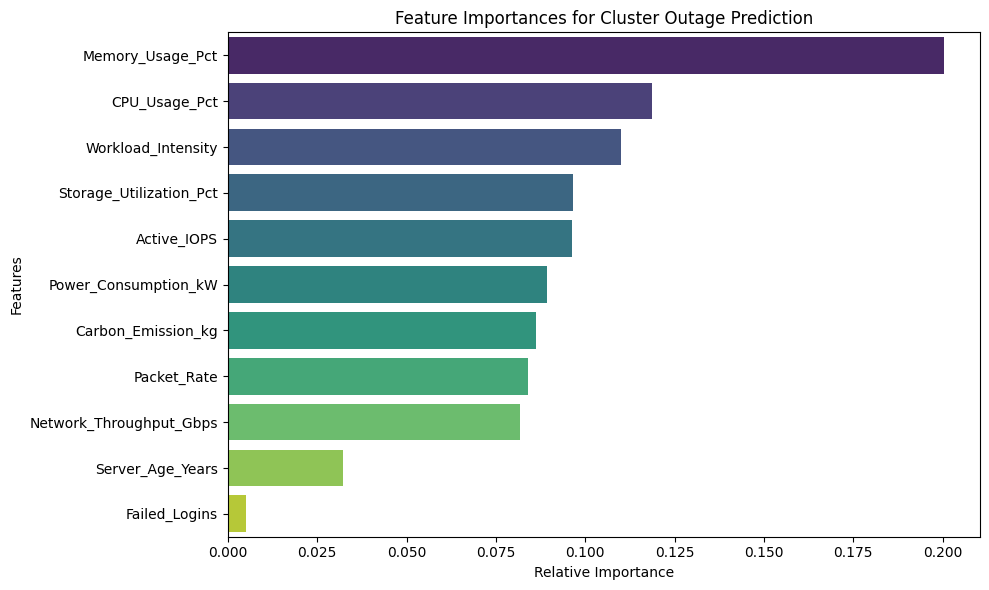

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

importance_df = pd.DataFrame(
    {"feature": np.array(feature_cols)[indices], "importance": importances[indices]}
)
sns.barplot(data=importance_df, x="importance", y="feature", color="steelblue")
plt.title("Random Forest feature importance for outage prediction")
plt.tight_layout()
plt.show()

### 5. Correlation Analysis of the Master Datacenter Telemetry
Inspect correlations between numeric telemetry fields. `Is_Outage` is derived from CPU and memory thresholds, so its correlation with those inputs is expected and is not independent evidence of predictive power.

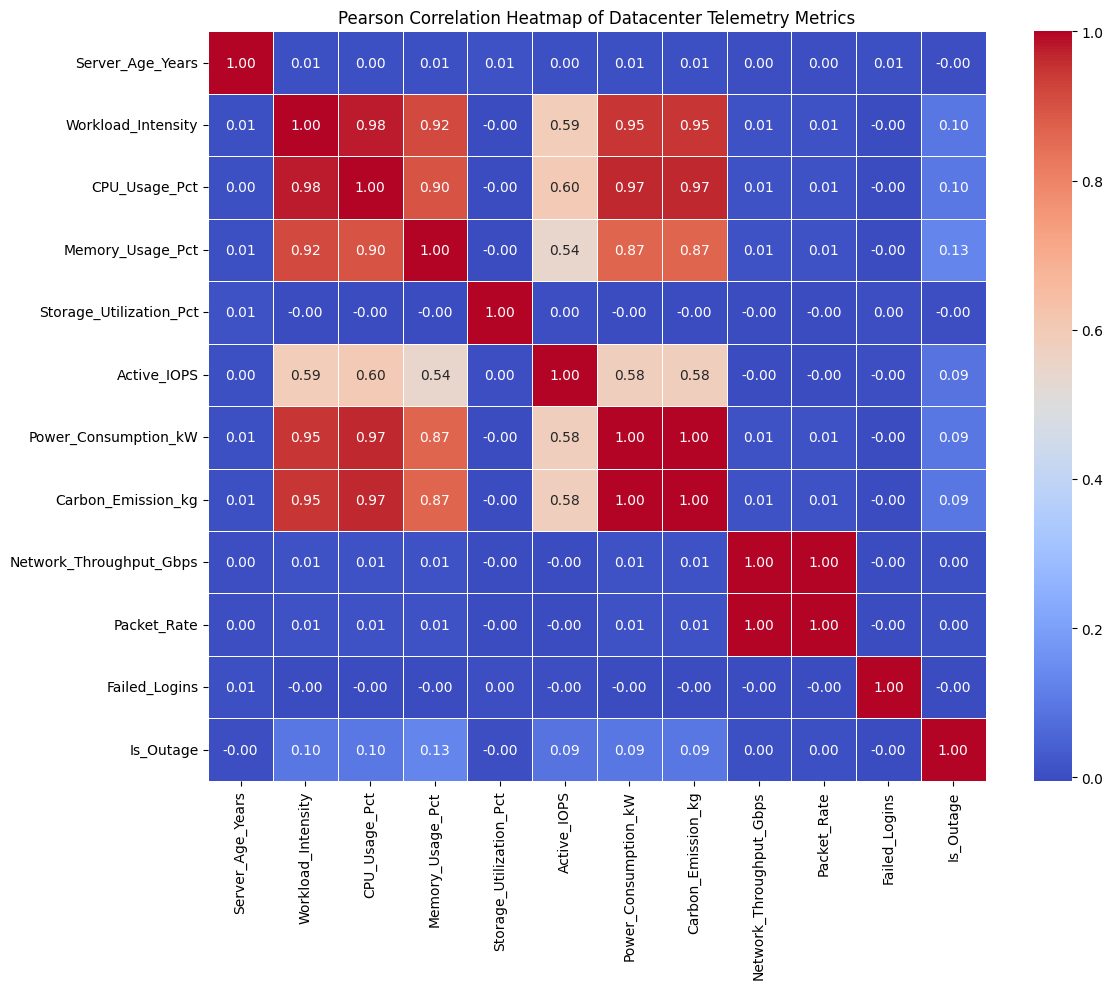

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter numeric columns for correlation analysis
numeric_cols = master_datacenter_df.select_dtypes(include=['float64', 'int64', 'int32']).columns
corr_matrix = master_datacenter_df[numeric_cols].corr()

# Plot correlation matrix heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Pearson Correlation Heatmap of Datacenter Telemetry Metrics')
plt.tight_layout()
plt.show()

### 6. Alternative Model Training & Evaluation
Compare linear, tree-based, and instance-based models on the same stratified holdout split. Scale only models that require it, and report precision, recall, and F1 for the outage class in addition to accuracy.

In [38]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42, class_weight="balanced"
    ),
    "Linear SVM": LinearSVC(
        max_iter=2000, random_state=42, class_weight="balanced", dual=False
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}

scaled_models = {"Logistic Regression", "Linear SVM", "K-Nearest Neighbors"}
comparison_results = [{"model": "Random Forest", **rf_metrics}]
for name, clf in models.items():
    train_features, test_features = (
        (X_train_scaled, X_test_scaled) if name in scaled_models else (X_train, X_test)
    )
    clf.fit(train_features, y_train)
    predictions = clf.predict(test_features)
    comparison_results.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, predictions),
            "outage_precision": precision_score(
                y_test, predictions, pos_label=1, zero_division=0
            ),
            "outage_recall": recall_score(
                y_test, predictions, pos_label=1, zero_division=0
            ),
            "outage_f1": f1_score(y_test, predictions, pos_label=1, zero_division=0),
        }
    )
comparison_df = pd.DataFrame(comparison_results).set_index("model")
comparison_df.sort_values("outage_f1", ascending=False)



========== Training Logistic Regression ==========
Accuracy Score: 63.91%
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.64      0.77     14282
           1       0.07      0.53      0.12       718

    accuracy                           0.64     15000
   macro avg       0.52      0.59      0.45     15000
weighted avg       0.92      0.64      0.74     15000


========== Training Gradient Boosting ==========
Accuracy Score: 96.47%
Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     14282
           1       0.93      0.28      0.43       718

    accuracy                           0.96     15000
   macro avg       0.95      0.64      0.71     15000
weighted avg       0.96      0.96      0.96     15000


========== Training Decision Tree ==========
Accuracy Score: 93.01%
Classification Report:
              precision    recall  f1-score   support

     